# 2. Policy Comparison

How much does the control policy matter? We compare the six rule-based reference
policies from `carla_gym/baselines.py` on synthetic Poisson traffic and on the real
packet-capture trace.

* Bandwidth-only heuristics (routing stays hop-count shortest path): `max_bandwidth`
  (equal split), `queue_proportional`, `min_bandwidth`, `random`.
* Routing-aware traffic-engineering heuristics: `load_aware_routing` (equal split,
  steers new packets around congested links) and `congestion_aware`
  (queue-proportional bandwidth plus load-aware routing).

All numbers below are computed when the notebook runs.

The `throughput` and `loss` columns are means of the per-step reward terms (ratios within one step), not the fraction of traffic delivered or dropped over the episode. For those, see the delivered / dropped tables in the README (`scripts/run_benchmark.py`, `scripts/evaluate_saved.py`).

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.env import CarlaGymEnv
from carla_gym.core.trace_traffic import TraceTrafficGenerator
from carla_gym.baselines import POLICIES
from carla_gym.utils.stats import ci95

plt.rcParams["figure.dpi"] = 100
print("policies:", list(POLICIES))

policies: ['random', 'min_bandwidth', 'max_bandwidth', 'queue_proportional', 'load_aware_routing', 'congestion_aware']


In [2]:
def run_policy(make_env, fn, episodes=5, steps=150, warmup=20, seed=42):
    rows = []
    for ep in range(episodes):
        env = make_env(seed + ep)
        obs, _ = env.reset(seed=seed + ep)
        rng = np.random.default_rng(seed + ep)
        for t in range(steps):
            action = fn(env, obs, rng)
            obs, reward, terminated, truncated, info = env.step(action)
            if t >= warmup:
                rows.append({
                    "episode": ep, "step": t, "reward": reward,
                    "throughput": info["reward_throughput"],
                    "loss": info["reward_loss"],
                    "latency": info["mean_latency_steps"],
                    "deadline_miss": info["reward_deadline_miss"],
                })
            if terminated or truncated:
                break
    return pd.DataFrame(rows)

## Synthetic Poisson traffic, bandwidth_budget=0.8

In [3]:
def summarize(results):
    out = pd.DataFrame({
        name: df[["reward", "throughput", "loss", "latency", "deadline_miss"]].mean()
        for name, df in results.items()
    }).T
    out["reward_ci95"] = [ci95(df.groupby("episode")["reward"].mean()) for df in results.values()]
    return out.sort_values("reward", ascending=False)

def make_synthetic_env(seed):
    return CarlaGymEnv(topology="grid", num_nodes=9, link_capacity=30, node_buffer=120,
                       bandwidth_budget=0.8, max_steps=150, seed=seed)

synthetic_results = {name: run_policy(make_synthetic_env, fn) for name, fn in POLICIES.items()}
synthetic_summary = summarize(synthetic_results)
synthetic_summary.round(3)

,reward,throughput,loss,latency,deadline_miss,reward_ci95
queue_proportional,0.402,0.806,0.125,3.877,0.185,0.022
congestion_aware,0.396,0.811,0.128,4.006,0.191,0.032
load_aware_routing,0.369,0.807,0.146,3.952,0.185,0.025
max_bandwidth,0.338,0.797,0.161,3.936,0.178,0.099
random,-0.896,0.428,0.599,11.635,0.490,0.050
min_bandwidth,-1.804,0.043,0.939,44.356,0.815,0.009


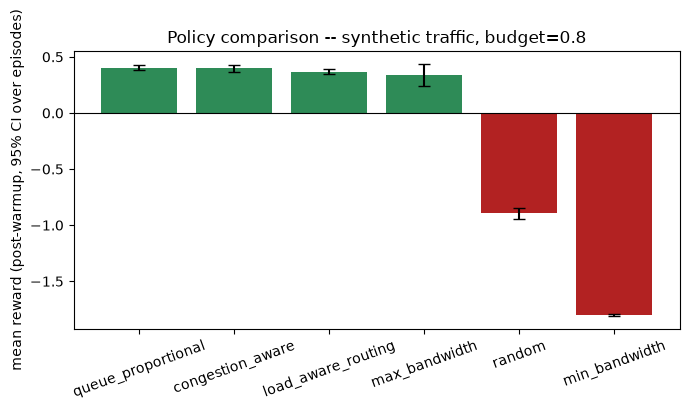

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["seagreen" if v > 0 else "firebrick" for v in synthetic_summary["reward"]]
ax.bar(synthetic_summary.index, synthetic_summary["reward"], yerr=synthetic_summary["reward_ci95"],
       capsize=4, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("mean reward (post-warmup, 95% CI over episodes)")
ax.set_title("Policy comparison -- synthetic traffic, budget=0.8")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Reward over time, all policies

Same traffic, different control strategies: the policy changes the whole
trajectory, not only the final average.

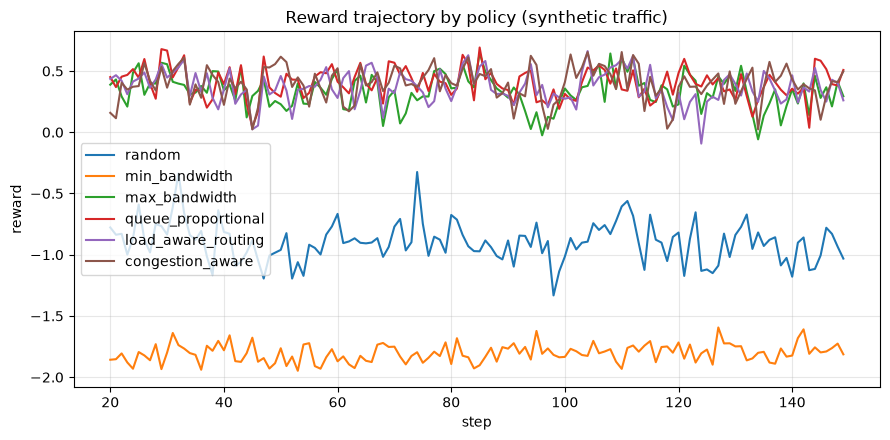

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, df in synthetic_results.items():
    series = df.groupby("step")["reward"].mean()
    ax.plot(series.index, series.values, label=name)
ax.set_xlabel("step")
ax.set_ylabel("reward")
ax.set_title("Reward trajectory by policy (synthetic traffic)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Throughput vs. loss trade-off

Each point is one policy's mean operating point. Good policies sit in
the top-left: high throughput, low loss.

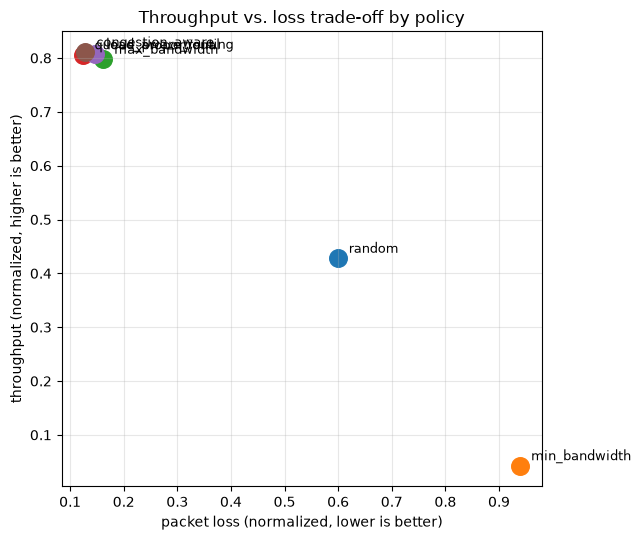

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in POLICIES:
    row = synthetic_summary.loc[name]
    ax.scatter(row["loss"], row["throughput"], s=160, label=name)
    ax.annotate(name, (row["loss"], row["throughput"]),
               textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xlabel("packet loss (normalized, lower is better)")
ax.set_ylabel("throughput (normalized, higher is better)")
ax.set_title("Throughput vs. loss trade-off by policy")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Real packet-capture trace, bandwidth_budget=0.5

Real traffic concentrates on fewer source/destination pairs than the synthetic
generator, so we also look at a tighter budget here.

In [7]:
TRACE_PATH = "data/pcap_trace.csv"
assert os.path.exists(TRACE_PATH), (
    "Run `python scripts/prepare_trace.py --in data/raw/output1.csv --out data/pcap_trace.csv` first."
)

def make_trace_env(seed):
    traffic = TraceTrafficGenerator(nodes=list(range(16)), csv_path=TRACE_PATH,
                                    target_load=110.0, seed=seed)
    return CarlaGymEnv(topology="grid", num_nodes=16, link_capacity=30, node_buffer=120,
                       bandwidth_budget=0.5, max_steps=150, traffic=traffic, seed=seed)

trace_results = {name: run_policy(make_trace_env, fn) for name, fn in POLICIES.items()}
trace_summary = summarize(trace_results)
trace_summary.round(3)

,reward,throughput,loss,latency,deadline_miss,reward_ci95
queue_proportional,-0.017,0.368,0.197,3.161,0.097,0.013
congestion_aware,-0.052,0.370,0.173,3.826,0.139,0.023
load_aware_routing,-0.263,0.334,0.247,5.859,0.208,0.027
max_bandwidth,-0.298,0.324,0.284,5.940,0.191,0.032
random,-0.406,0.290,0.301,6.596,0.239,0.033
min_bandwidth,-0.997,0.069,0.437,14.539,0.486,0.038


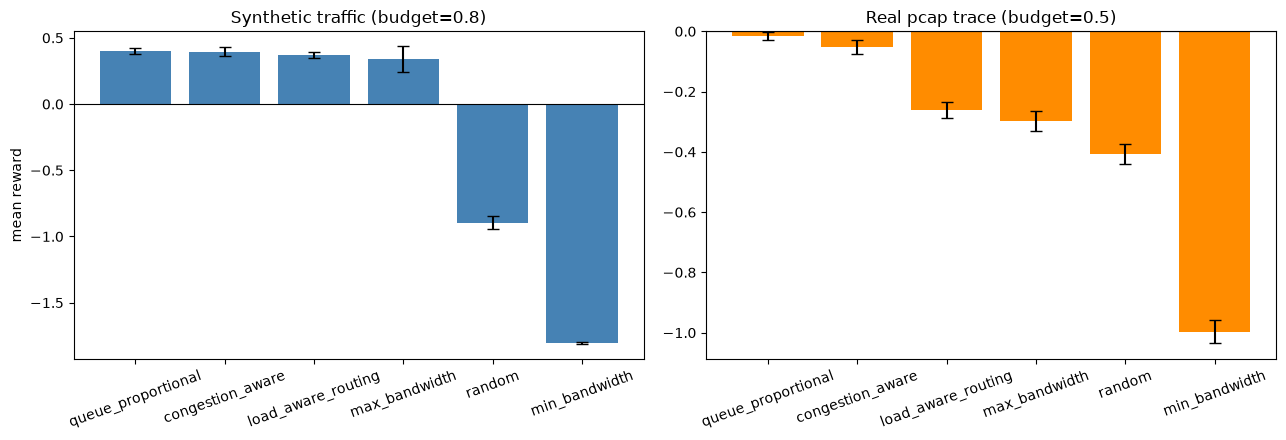

synthetic, budget 0.8: best = queue_proportional (+0.402); queue_proportional - max_bandwidth = +0.064 (intervals overlap, not a clear difference)
pcap trace, budget 0.5: best = queue_proportional (-0.017); queue_proportional - max_bandwidth = +0.282 (intervals do not overlap)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colors = ["seagreen" if v > synthetic_summary["reward"].min() else "firebrick"
         for v in synthetic_summary["reward"]]
axes[0].bar(synthetic_summary.index, synthetic_summary["reward"], yerr=synthetic_summary["reward_ci95"], capsize=4, color="steelblue")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Synthetic traffic (budget=0.8)")
axes[0].set_ylabel("mean reward")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(trace_summary.index, trace_summary["reward"], yerr=trace_summary["reward_ci95"], capsize=4, color="darkorange")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Real pcap trace (budget=0.5)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

for label, summ in [("synthetic, budget 0.8", synthetic_summary), ("pcap trace, budget 0.5", trace_summary)]:
    qp, mx = summ.loc["queue_proportional"], summ.loc["max_bandwidth"]
    gap = qp["reward"] - mx["reward"]
    clear = abs(gap) > qp["reward_ci95"] + mx["reward_ci95"]
    print(f"{label}: best = {summ.index[0]} ({summ['reward'].iloc[0]:+.3f}); "
          f"queue_proportional - max_bandwidth = {gap:+.3f} "
          f"({'intervals do not overlap' if clear else 'intervals overlap, not a clear difference'})")